# Chapitre 8 · Apprendre avec scikit-learn

Une boutique veut repérer, au moment de la commande, les livraisons qui risquent
d'arriver en retard. Vous allez passer d'un DataFrame à un modèle testé, puis
comparer plusieurs familles d'algorithmes.

Les données de livraison, d'énergie et les nuages de points sont **simulés**.
Les scores servent à comprendre le protocole. Ils ne mesurent la performance
d'aucun service réel. Les cellules s'exécutent dans l'ordre, sans fichier de données
ni accès réseau après installation.

## Préparer l'environnement

Dans l'environnement du cours, installer avec
<code>python -m pip install numpy pandas matplotlib scikit-learn jupyterlab</code>.
Le nom à installer est **scikit-learn** et le nom à importer est **sklearn**.
Le notebook a été exécuté avec scikit-learn 1.4.2.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from IPython.display import display
from sklearn.base import clone
from sklearn.cluster import DBSCAN, KMeans
from sklearn.compose import ColumnTransformer
from sklearn.datasets import make_moons
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression, Ridge
from sklearn.metrics import (
    ConfusionMatrixDisplay, balanced_accuracy_score, confusion_matrix,
    f1_score, mean_absolute_error, precision_score, recall_score,
    root_mean_squared_error,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

%matplotlib inline
plt.rcParams.update({
    "figure.dpi": 130, "font.size": 11, "axes.spines.top": False,
    "axes.spines.right": False, "axes.labelcolor": "#2e2d29",
})
seed = 8
print("scikit-learn", sklearn.__version__)

scikit-learn 1.4.2


## 1. Définir ce que le modèle peut savoir

Une ligne représente une commande. La distance estimée (km), le nombre de
colis, la charge prévue (indice de 0 à 10) et le mode sont connus à la prise
de commande. La cible <code>is_late</code> vaut 1 si la livraison arrive après
l'heure promise, 0 sinon. Elle est observée après livraison.

La simulation crée un risque croissant avec la distance et la charge. Elle
ajoute une interaction et une part aléatoire. Quelques champs sont ensuite
masqués pour travailler l'imputation. Les commandes sont simulées comme
indépendantes, ce qui permet ici une séparation aléatoire.

In [2]:
rng = np.random.default_rng(seed)
n_orders = 1000
distance_km = rng.uniform(1, 55, n_orders).round(1)
parcel_count = rng.integers(1, 9, n_orders)
load_index = rng.integers(0, 11, n_orders)
delivery_mode = rng.choice(["standard", "express"], n_orders, p=[0.73, 0.27])
score = (
    -2.35 + 0.052 * (distance_km - 20) + 0.23 * (parcel_count - 3)
    + 0.32 * (load_index - 5) - 0.9 * (delivery_mode == "express")
    + 1.25 * ((distance_km > 37) & (load_index > 6))
)
late_probability = 1 / (1 + np.exp(-score))
orders = pd.DataFrame({
    "distance_km": distance_km, "parcel_count": parcel_count, "load_index": load_index,
    "delivery_mode": delivery_mode, "is_late": rng.binomial(1, late_probability),
})
orders.loc[rng.random(n_orders) < 0.08, "distance_km"] = np.nan
orders.loc[rng.random(n_orders) < 0.04, "delivery_mode"] = np.nan
display(orders.head(4))

,distance_km,parcel_count,load_index,delivery_mode,is_late
0,18.7,7,9,standard,0
1,54.3,4,0,standard,0
2,18.2,4,10,standard,0
3,43.6,4,6,standard,0


**À vous.** La colonne « durée réelle » existe dans l'historique. Peut-elle
être ajoutée aux entrées du modèle ?

<details><summary>Correction</summary>
La durée réelle n'est connue qu'après livraison. L'utiliser à la prise de
commande serait une fuite d'information. La distance estimée est disponible
au bon moment.
</details>

In [3]:
numeric_features = ["distance_km", "parcel_count", "load_index"]
categorical_features = ["delivery_mode"]
X = orders[numeric_features + categorical_features]
y = orders["is_late"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=seed
)
print("Apprentissage :", X_train.shape)
print("Test réservé :", X_test.shape)
print("Part de retards en apprentissage :", round(y_train.mean(), 3))
display(X_train.isna().sum().rename("Champs manquants"))

Apprentissage : (750, 4)
Test réservé : (250, 4)
Part de retards en apprentissage : 0.233


distance_km      61
parcel_count      0
load_index        0
delivery_mode    19
Name: Champs manquants, dtype: int64

On choisit les réglages avec les seules lignes d'apprentissage. La
stratification conserve à peu près la proportion de chaque classe. Avec des
données datées ou plusieurs lignes par client, adapter le découpage à l'usage
prévu. La stratification ne suffit pas à protéger des fuites entre périodes
ou entre clients.

## 2. Apprendre les transformations avec le modèle

<strong>fit</strong> apprend les paramètres. <strong>transform</strong> les
réutilise pour convertir des lignes. <strong>predict</strong> utilise le modèle
ajusté pour produire une sortie. Le centreur du chapitre 4 suivait déjà ce
principe.

L'imputation numérique remplace les absences par la médiane apprise.
La standardisation soustrait la moyenne puis divise par l'écart-type appris
après imputation. Le mode manquant est remplacé par la catégorie la plus
fréquente. Le one-hot représente ensuite chaque catégorie connue par une
colonne 0/1.

In [4]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features),
])

Les branches du <code>ColumnTransformer</code> travaillent sur des colonnes
différentes, puis leurs sorties sont concaténées. Le <code>Pipeline</code>
les relie au modèle. Chaque ajustement en validation croisée réapprend la
médiane, l'échelle et les catégories sur le pli d'apprentissage courant.

In [5]:
base_pipeline = Pipeline([
    ("preprocess", preprocessor),
    ("model", LogisticRegression(solver="liblinear", max_iter=1000)),
])
logistic_pipeline = clone(base_pipeline).fit(X_train, y_train)

**À vous.** Prévoyez ce qui arrive pour une distance manquante et un nouveau
mode « courier ». Inspectez la sortie de <code>transform</code>.

In [6]:
X_new = pd.DataFrame({
    "distance_km": [24.0, np.nan], "parcel_count": [2, 4], "load_index": [3, 8],
    "delivery_mode": ["standard", "courier"],
})
fitted_preprocessor = logistic_pipeline.named_steps["preprocess"]
feature_names = fitted_preprocessor.get_feature_names_out()
display(pd.DataFrame(fitted_preprocessor.transform(X_new), columns=feature_names).round(2))
print("Ordre des classes :", logistic_pipeline.classes_)
print("Probabilités prévues :")
print(logistic_pipeline.predict_proba(X_new).round(3))

Ordre des classes : [0 1]
Probabilités prévues :
[[0.956 0.044]
 [0.579 0.421]]


,num__distance_km,num__parcel_count,num__load_index,cat__delivery_mode_express,cat__delivery_mode_standard
0,-0.20,-1.18,-0.68,0.0,1.0
1,-0.04,-0.27,0.97,0.0,0.0


Le mode inédit donne zéro dans les deux colonnes one-hot connues. La distance
absente est imputée avec la médiane apprise. Sur des données réelles, surveiller
la fréquence de ces catégories inconnues et vérifier que leur traitement reste
adapté.

### Intégrer une transformation déterministe

<code>FunctionTransformer</code> rend une fonction compatible avec un pipeline.
Ici, le logarithme de 1 plus le nombre de colis réduit l'écart entre grandes
valeurs. La quantité est supposée non négative. Cette variante peut être
insérée après l'imputation dans une branche qui ne contient que des quantités
non négatives. Elle sert d'essai indépendant.

In [7]:
log_transformer = FunctionTransformer(np.log1p, feature_names_out="one-to-one")
quantities = np.array([[0], [1], [9], [99]])
print(log_transformer.fit_transform(quantities).round(2).ravel())

[0.   0.69 2.3  4.61]


## 3. Modèles linéaires

### Linear Regression et Ridge

On reprend l'idée du bâtiment du chapitre 7. La cible numérique est une
consommation en kWh. La température prévue et les heures d'ouverture sont
connues avant la journée. Les 60 premières journées forment l'apprentissage,
les 20 suivantes l'évaluation de cet exemple.

La Linear Regression ajuste des coefficients pour minimiser la somme des
carrés des résidus. Ridge ajoute une pénalité sur la somme des carrés des
coefficients. Augmenter <code>alpha</code> favorise des coefficients plus
petits. Standardiser dans le pipeline donne un sens comparable à cette
pénalisation. La MAE est la moyenne des erreurs absolues. La RMSE prend la racine de
la moyenne des carrés des erreurs. Toutes deux sont en kWh ici.
Les trois méthodes ci-dessous sont fixées avant l'évaluation.

In [8]:
energy_rng = np.random.default_rng(18)
temperature_c = energy_rng.normal(15, 6, 80)
open_hours = energy_rng.integers(4, 13, 80)
X_energy = pd.DataFrame({"temperature_c": temperature_c, "open_hours": open_hours})
y_energy = 126 - 2.8 * temperature_c + 4.2 * open_hours + energy_rng.normal(0, 7, 80)
X_energy_train, X_energy_test = X_energy.iloc[:60], X_energy.iloc[60:]
y_energy_train, y_energy_test = y_energy[:60], y_energy[60:]

regression_models = {
    "Mean baseline": DummyRegressor(strategy="mean"),
    "Linear Regression": LinearRegression(),
    "Ridge": Pipeline([("scaler", StandardScaler()), ("model", Ridge(alpha=10))]),
}
regression_scores = {}
for name, model in regression_models.items():
    model.fit(X_energy_train, y_energy_train)
    energy_predictions = model.predict(X_energy_test)
    regression_scores[name] = {
        "MAE (kWh)": mean_absolute_error(y_energy_test, energy_predictions),
        "RMSE (kWh)": root_mean_squared_error(y_energy_test, energy_predictions),
    }
display(pd.DataFrame.from_dict(regression_scores, orient="index").round(2))

,MAE (kWh),RMSE (kWh)
Mean baseline,21.39,25.33
Linear Regression,7.44,8.98
Ridge,8.31,9.82


### Logistic Regression

Un score linéaire z est converti en probabilité par la sigmoïde
$1/(1+e^{-z})$. L'ajustement cherche des coefficients qui attribuent une
probabilité élevée aux classes observées, avec une pénalité dans
<code>LogisticRegression</code>. Ici, un score z de 0 donne une probabilité
de 0,5. Un coefficient positif augmente le score à variables transformées
inchangées. La relation estimée ne suffit pas à établir une causalité.

**À vous.** Que change un seuil de 0,3 au lieu de 0,5 ?
<details><summary>Correction</summary>
Les scores du modèle restent identiques. Un seuil plus bas signale au moins autant de commandes. Il peut repérer
davantage de retards et augmenter les fausses alertes.
Le seuil se choisit sur validation, selon le coût des deux erreurs.
</details>

## 4. K-Nearest Neighbors (KNN)

KNN mémorise les exemples étiquetés. Pour une nouvelle ligne, il calcule les
distances, retient les k plus proches, puis vote. En régression, il peut faire
la moyenne des cibles voisines. Pour un point 4 et les points 1, 3, 5, 8 de
classes 0, 1, 1, 0, les distances sont 3, 1, 1 et 4. Avec k = 3, le vote
donne 1. La mise à l'échelle compte car une variable de grande amplitude
peut dominer la distance.

In [9]:
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit([[1], [3], [5], [8]], [0, 1, 1, 0])
distances, indices = knn.kneighbors([[4]])
print("Distances retenues :", distances[0])
print("Indices des voisins :", indices[0])
print("Classe prévue :", knn.predict([[4]])[0])

Distances retenues : [1. 1. 3.]
Indices des voisins : [1 2 0]
Classe prévue : 1


## 5. Arbres et ensembles

Un Decision Tree teste des seuils et choisit celui qui améliore le plus la pureté
des groupes résultants. Pour la classification, l'impureté de Gini est
$1-\sum_c p_c^2$. Le score d'une coupure est une moyenne des impuretés
pondérée par les tailles des groupes. À la prédiction, on suit les règles
jusqu'à une feuille. Une feuille de classification utilise les proportions
de classes qu'elle contient. Une feuille de régression avec erreur
quadratique prédit la moyenne locale.

Random Forest ajuste plusieurs arbres sur des échantillons tirés avec remise.
À chaque coupure, chaque arbre examine un sous-ensemble aléatoire de
variables. La classe finale maximise la probabilité moyenne de la forêt.

Le Gradient Boosting ajoute les arbres l'un après l'autre pour corriger la
perte du modèle courant. En régression quadratique, les corrections ciblent
les résidus. En classification, elles ciblent le gradient négatif de la
perte, qui indique dans quel sens corriger les scores.

In [10]:
X_tree = [[1], [2], [3], [8], [9], [10]]
y_tree = [0, 0, 0, 1, 1, 1]
tree = DecisionTreeClassifier(max_depth=1, random_state=seed).fit(X_tree, y_tree)
print("Seuil appris :", tree.tree_.threshold[0])
print("Classes prévues pour 4 et 9 :", tree.predict([[4], [9]]))

Seuil appris : 5.5
Classes prévues pour 4 et 9 : [0 1]


Pour retrouver le premier pas d'un boosting de régression à la main, prendre
les cibles [2, 4, 9]. La moyenne initiale vaut 5. Les résidus valent
[-3, -1, 4]. Si un arbre prédit +4 pour la troisième ligne, un pas de 0,1
fait passer sa prédiction de 5 à 5,4.

## 6. Marges et modèles probabilistes

### SVM et noyau RBF

Le Linear SVM cherche une frontière qui laisse une marge large, tout en
pénalisant les observations dans la marge ou du mauvais côté. Les vecteurs
de support sont les observations qui interviennent dans la frontière
apprise. C règle le compromis entre marge et erreurs. Le noyau RBF
$\exp(-\gamma\|x-x'\|^2)$ compare les points selon leur distance.
Un gamma élevé rend l'influence plus locale.

Les deux panneaux suivants illustrent les frontières apprises **sur les
points affichés**. Ils servent à voir la géométrie des modèles.

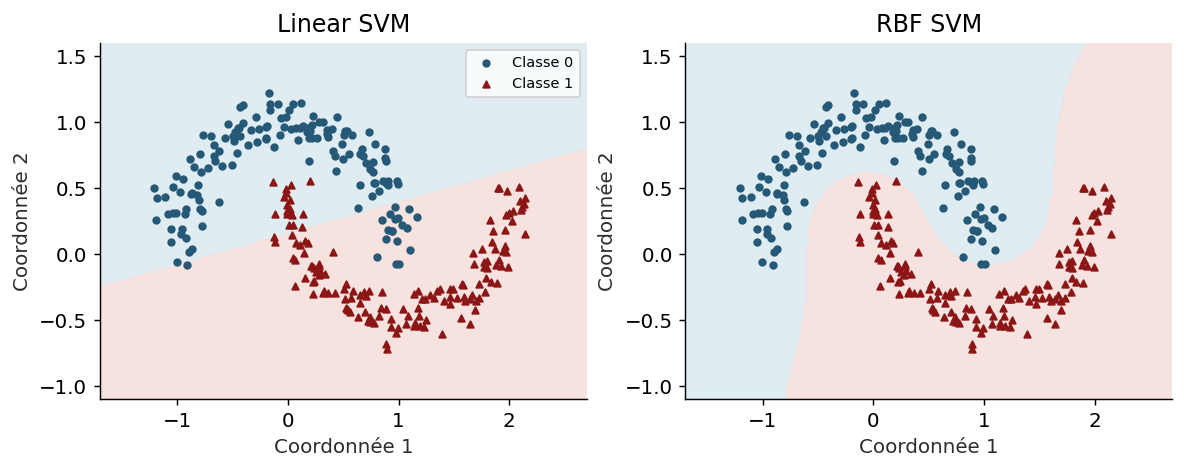

In [11]:
points, labels = make_moons(n_samples=300, noise=0.10, random_state=seed)
grid_x, grid_y = np.meshgrid(
    np.linspace(-1.7, 2.7, 240), np.linspace(-1.1, 1.6, 190)
)
grid_points = np.c_[grid_x.ravel(), grid_y.ravel()]
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5), layout="constrained")
for ax, kernel in zip(axes, ["linear", "rbf"]):
    svm = Pipeline([("scaler", StandardScaler()), ("model", SVC(kernel=kernel))])
    svm.fit(points, labels)
    grid_predictions = svm.predict(grid_points).reshape(grid_x.shape)
    ax.contourf(grid_x, grid_y, grid_predictions, levels=[-0.5, 0.5, 1.5],
                colors=["#dceaf1", "#f6dfdb"], alpha=0.9)
    for class_id, color, marker in [(0, "#265977", "o"), (1, "#8c1515", "^")]:
        pts = points[labels == class_id]
        ax.scatter(pts[:, 0], pts[:, 1], c=color, marker=marker,
                   s=13, label=f"Classe {class_id}")
    ax.set(title={"linear": "Linear SVM", "rbf": "RBF SVM"}[kernel], xlabel="Coordonnée 1", ylabel="Coordonnée 2")
    ax.set_xlim(-1.7, 2.7)
    ax.set_ylim(-1.1, 1.6)
axes[0].legend(loc="upper right", fontsize=8)
plt.show()

### Gaussian Naive Bayes

On estime une proportion de départ pour chaque classe. Dans chaque classe,
on ajuste une loi normale par variable (moyenne et variance). Pour une
nouvelle ligne, on multiplie la proportion de départ par les densités de
ses valeurs. Cette multiplication suppose les variables indépendantes
**conditionnellement à la classe**. La classe au produit le plus grand est
retenue. En pratique, le calcul utilise des logarithmes pour stabiliser
les produits.

L'essai utilise deux variables numériques et de très petits groupes pour
rendre le calcul lisible. Des variables presque redondantes peuvent donner
trop de poids à la même information.

In [12]:
X_bayes = [[1, 2], [2, 1], [2, 3], [7, 7], [8, 6], [9, 8]]
y_bayes = [0, 0, 0, 1, 1, 1]
bayes = GaussianNB().fit(X_bayes, y_bayes)
print("Moyennes par classe :")
print(bayes.theta_.round(2))
print("Classes pour [2, 2] et [8, 7] :", bayes.predict([[2, 2], [8, 7]]))

Moyennes par classe :
[[1.67 2.  ]
 [8.   7.  ]]
Classes pour [2, 2] et [8, 7] : [0 1]


## 7. Comparer les modèles et leurs réglages

### Choisir la métrique avant de comparer

| Tâche | Métriques | Question |
| --- | --- | --- |
| Régression | MAE, RMSE | Quelle est l'erreur en unités de la cible ? La RMSE donne plus de poids aux grands écarts. |
| Classification | Recall, precision, F1, balanced accuracy | Combien de positifs repère-t-on, avec combien de fausses alertes ? |
| Classement par score | ROC AUC | Les positifs reçoivent-ils des scores plus élevés que les négatifs ? |
| Regroupement | Silhouette score | Les points sont-ils proches de leur groupe et éloignés des autres groupes ? |

F1 est la moyenne harmonique de precision et recall : $2PR/(P+R)$ si
$P+R>0$. Il baisse dès que l'une des deux mesures est faible. La ROC AUC
évalue le classement produit par des scores à travers les seuils. Le
silhouette score repose sur les distances. Si on écarte les points de bruit
de DBSCAN, indiquer aussi la proportion de points retenus.


La **balanced accuracy** est la moyenne des rappels des deux classes.
Pour les retards, le rappel est la part des retards détectés. Pour les
commandes à l'heure, c'est la part correctement laissée sans alerte.
Une référence prédisant toujours la même classe vaut 0,50 si les deux
classes sont présentes.

**À vous.** Parmi 100 commandes, 20 sont en retard. Le modèle en détecte 12
et signale aussi 8 commandes à l'heure. Calculez le rappel des retards et
la balanced accuracy.
<details><summary>Correction</summary>
Rappel des retards = 12/20 = 60 %. Rappel des commandes à l'heure =
72/80 = 90 %. Balanced accuracy = (60 % + 90 %)/2 = 75 %.
</details>

Quatre plis stratifiés donnent les mêmes groupes de validation à tous les
candidats. <code>model__C</code> désigne le paramètre C de l'étape
<code>model</code>. Dans chaque dictionnaire, la grille combine les valeurs.
L'ensemble de test reste fermé pendant cette étape.

In [13]:
param_grid = [
    {"model": [DummyClassifier(strategy="most_frequent")]},
    {"model": [LogisticRegression(solver="liblinear", max_iter=1000)],
     "model__C": [0.1, 1, 10]},
    {"model": [KNeighborsClassifier()],
     "model__n_neighbors": [5, 15, 35]},
    {"model": [DecisionTreeClassifier(random_state=seed)],
     "model__max_depth": [2, 4, 8]},
    {"model": [RandomForestClassifier(n_estimators=100, random_state=seed)],
     "model__max_depth": [4, 8]},
    {"model": [GradientBoostingClassifier(n_estimators=80, max_depth=2,
                                            random_state=seed)],
     "model__learning_rate": [0.05, 0.10]},
    {"model": [SVC(kernel="rbf")],
     "model__C": [0.5, 2]},
]

In [14]:
cv_splitter = StratifiedKFold(n_splits=4, shuffle=True, random_state=seed)
search = GridSearchCV(
    base_pipeline, param_grid, cv=cv_splitter, scoring="balanced_accuracy", refit=True
)
search.fit(X_train, y_train)
cv_results = pd.DataFrame(search.cv_results_)
cv_results["model_family"] = cv_results["param_model"].map(
    lambda estimator: type(estimator).__name__
)
best_by_family = (
    cv_results.sort_values("rank_test_score", kind="stable")
    .drop_duplicates("model_family")[["model_family", "mean_test_score", "std_test_score"]]
)
display(best_by_family.round(3).reset_index(drop=True))
print("Meilleur réglage :", search.best_params_)

Meilleur réglage : {'model': RandomForestClassifier(random_state=8), 'model__max_depth': 8}


,model_family,mean_test_score,std_test_score
0,RandomForestClassifier,0.698,0.077
1,LogisticRegression,0.687,0.081
2,KNeighborsClassifier,0.680,0.061
3,DecisionTreeClassifier,0.678,0.047
4,GradientBoostingClassifier,0.665,0.050
5,SVC,0.658,0.065
6,DummyClassifier,0.500,0.000


La moyenne sur quatre plis sert au choix. Les valeurs présentées par famille
sont les meilleures parmi les réglages essayés. L'écart-type décrit la
dispersion entre plis. Un petit écart entre candidats ne suffit pas à établir
la supériorité d'une famille. Avec <code>refit=True</code>, le meilleur
pipeline est réajusté sur toutes les lignes d'apprentissage.

### Ouvrir le test après le choix

On évalue une seule fois le pipeline retenu. Une fausse alerte mobilise une
vérification, un retard manqué ne sera pas signalé. La matrice indique
combien d'erreurs de chaque type ont été commises.

Balanced accuracy : 0.702
Précision des alertes : 0.6
Rappel des retards : 0.508
F1 : 0.55
[[171  20]
 [ 29  30]]


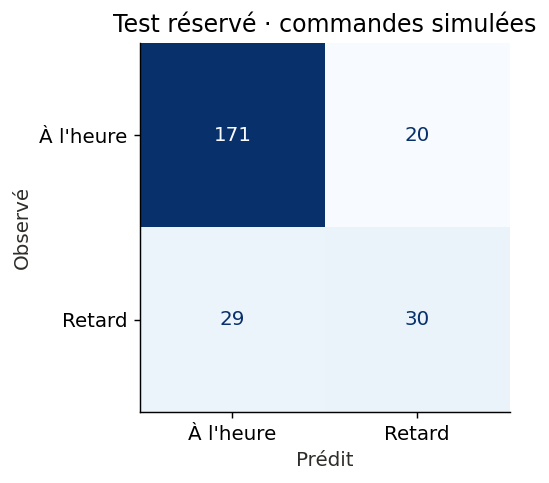

In [15]:
best_pipeline = search.best_estimator_
predictions = best_pipeline.predict(X_test)
matrix = confusion_matrix(y_test, predictions, labels=[0, 1])
print("Balanced accuracy :", round(balanced_accuracy_score(y_test, predictions), 3))
print("Précision des alertes :", round(precision_score(y_test, predictions), 3))
print("Rappel des retards :", round(recall_score(y_test, predictions), 3))
print("F1 :", round(f1_score(y_test, predictions), 3))
print(matrix)
fig, ax = plt.subplots(figsize=(4.4, 3.6), layout="constrained")
ConfusionMatrixDisplay(matrix, display_labels=["À l'heure", "Retard"]).plot(
    ax=ax, cmap="Blues", colorbar=False
)
ax.set(xlabel="Prédit", ylabel="Observé", title="Test réservé · commandes simulées")
plt.show()

**Vérification.** La diagonale contient les décisions correctes. La cellule
en bas à gauche compte les retards manqués. Si le rappel est insuffisant
pour l'usage, ouvrir une nouvelle phase de validation pour retravailler le
seuil ou les variables. Un test déjà utilisé pour ajuster la décision doit
être remplacé par un jeu final indépendant.

## 8. Apprentissage sans cible

On réutilise les deux croissants de l'exemple SVM, cette fois sans fournir
les étiquettes aux méthodes.

**K-means.** Choisir k centres, affecter chaque point au plus proche,
recalculer chaque centre comme moyenne de son groupe et répéter. Pour
[0, 2, 8, 10] et des centres initiaux 0 et 8, on obtient {0, 2} et {8, 10},
donc les centres 1 et 9. L'inertie est la somme des distances au carré
jusqu'aux centres. Elle baisse en général avec k et ne suffit pas à choisir k.

**DBSCAN.** Un point est cœur si son voisinage de rayon eps contient au moins
min_samples points en le comptant lui-même. Les cœurs reliés forment des
groupes, auxquels s'ajoutent les points de bord à portée d'un cœur. Les points
non rattachés sont étiquetés -1. L'échelle des variables fixe le sens d'eps.

Effectifs DBSCAN : {-1: 2, 0: 148, 1: 150}


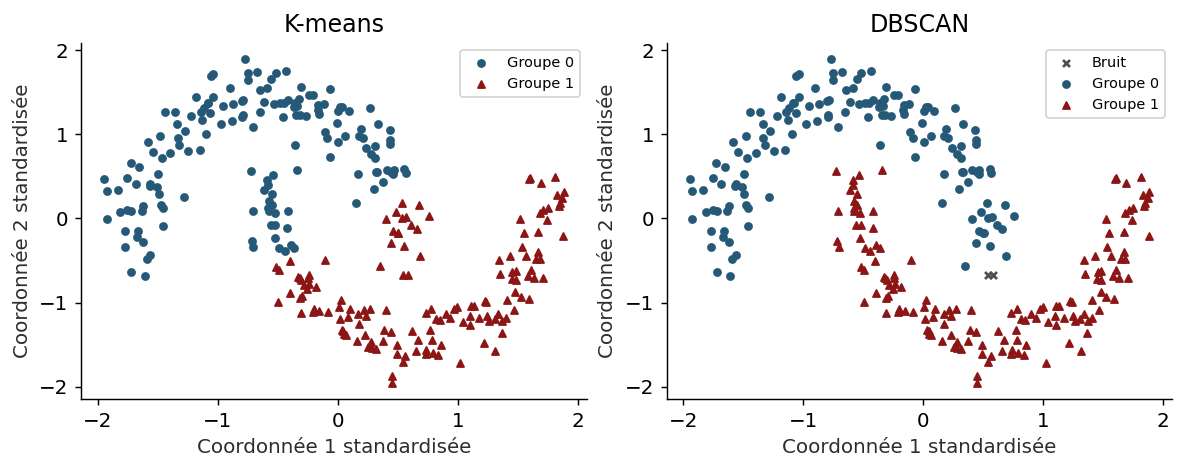

In [16]:
Z = StandardScaler().fit_transform(points)
kmeans = KMeans(n_clusters=2, n_init=10, random_state=seed)
dbscan = DBSCAN(eps=0.29, min_samples=5)
kmeans_labels = kmeans.fit_predict(Z)
dbscan_labels = dbscan.fit_predict(Z)

fig, axes = plt.subplots(1, 2, figsize=(9, 3.5), layout="constrained")
for ax, title, cluster_labels in zip(axes, ["K-means", "DBSCAN"], [kmeans_labels, dbscan_labels]):
    for cluster_id in sorted(set(cluster_labels)):
        pts = Z[cluster_labels == cluster_id]
        if cluster_id == -1:
            color, marker, name = "#505050", "x", "Bruit"
        else:
            color = ["#265977", "#8c1515", "#397553"][cluster_id % 3]
            marker = ["o", "^", "s"][cluster_id % 3]
            name = f"Groupe {cluster_id}"
        ax.scatter(pts[:, 0], pts[:, 1], c=color, marker=marker, s=15, label=name)
    ax.set(title=title, xlabel="Coordonnée 1 standardisée",
           ylabel="Coordonnée 2 standardisée")
    ax.legend(loc="upper right", fontsize=8)
plt.show()
print("Effectifs DBSCAN :", pd.Series(dbscan_labels).value_counts().sort_index().to_dict())

La forme des deux groupes est courbe. Avec deux centres, K-means coupe le
nuage selon la proximité aux centres. DBSCAN peut suivre les croissants
par connexions de voisinage. Un eps trop grand risque de les fusionner.
Avec des densités très différentes, un rayon unique peut être mal adapté.
Les numéros de groupe sont arbitraires et leur signification vient des
observations qui les composent.

### PCA · Résumer plusieurs colonnes

On centre les colonnes et on cherche l'axe de variance maximale. L'axe
suivant est orthogonal au premier. Chaque observation est projetée sur
les axes conservés. Si les unités ou ordres de grandeur diffèrent, la
standardisation est souvent pertinente avant la PCA.

Le nuage suivant est exprimé en unités comparables. La première composante
est une coordonnée numérique par ligne. Sa part de variance mesure la
dispersion représentée par cet axe. Pour une tâche supervisée, placer
la PCA dans le pipeline et vérifier le score en validation.

Formes : (140, 2) → (140, 1)


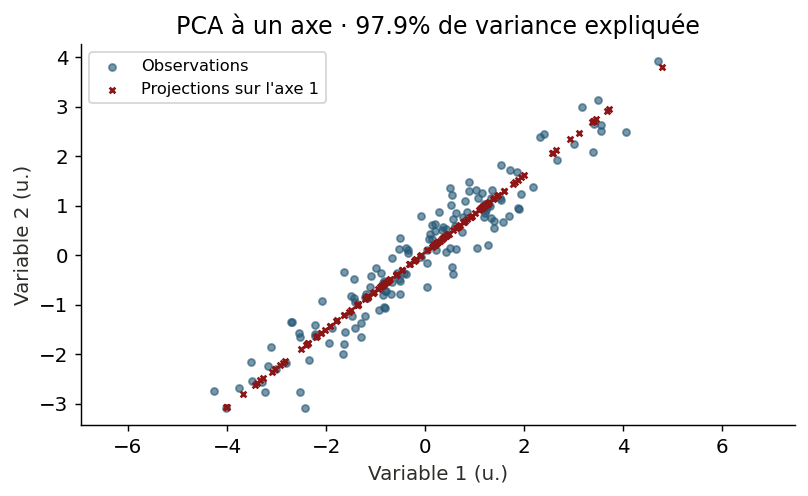

In [17]:
pca_rng = np.random.default_rng(31)
signal = pca_rng.normal(0, 2.0, 140)
cloud = np.c_[signal, 0.75 * signal + pca_rng.normal(0, 0.45, 140)]
pca = PCA(n_components=1)
components = pca.fit_transform(cloud)
projected = pca.inverse_transform(components)
explained_variance = pca.explained_variance_ratio_[0]
fig, ax = plt.subplots(figsize=(6.1, 3.7), layout="constrained")
ax.scatter(cloud[:, 0], cloud[:, 1], s=15, color="#265977", alpha=0.62,
           label="Observations")
ax.scatter(projected[:, 0], projected[:, 1], s=10, color="#8c1515",
           marker="x", label="Projections sur l'axe 1")
ax.set(title=f"PCA à un axe · {explained_variance:.1%} de variance expliquée",
       xlabel="Variable 1 (u.)", ylabel="Variable 2 (u.)")
ax.legend(loc="upper left", fontsize=9)
ax.set_aspect("equal", adjustable="datalim")
plt.show()
print("Formes :", cloud.shape, "→", components.shape)

## 9. S'exercer et vérifier

1. Pour un modèle livré chaque lundi, expliquez pourquoi séparer par semaine
   peut être préférable à mélanger toutes les lignes. Définissez ce qu'est une
   prédiction disponible au moment de la commande.
2. Écrivez un pipeline pour des capteurs avec deux colonnes numériques et une
   catégorie d'appareil. Indiquez précisément où se font imputation et encodage.
3. Ajoutez une valeur 25 à la grille de k pour les voisins, puis comparez les
   scores sur les plis de l'apprentissage. Gardez cette exploration dans une
   copie du notebook. Le test de cet exemple a déjà été ouvert.
4. Pour DBSCAN sur [0, 0.2, 0.4, 2], prenez eps = 0.25 et min_samples = 3.
   Identifiez les cœurs, les bords et le bruit à la main.

<details><summary>Éléments de correction</summary>

1. Entraîner sur le passé et valider sur des semaines suivantes simule
   l'usage prévu. Les champs créés après la commande sont indisponibles.
2. Une branche numérique impute puis standardise. La branche de l'appareil
   impute et encode. Le ColumnTransformer assemble leurs colonnes et le
   Pipeline l'ajuste avec le modèle dans chaque pli.
3. Étendre la liste des valeurs de model__n_neighbors puis relancer
   GridSearchCV sur X_train et y_train. Comparer les moyennes de CV et
   conserver un nouveau test si un nouveau résultat final est requis.
4. 0.2 voit 0, 0.2 et 0.4. C'est le seul cœur. 0 et 0.4 sont des bords.
   2 est isolé et porte l'étiquette -1.
</details>

[Guide scikit-learn](https://scikit-learn.org/1.4/user_guide.html) ·
[Pipelines et paramètres imbriqués](https://scikit-learn.org/1.4/modules/compose.html) ·
[Fuites d'information](https://scikit-learn.org/1.4/common_pitfalls.html) ·
[Validation croisée](https://scikit-learn.org/1.4/modules/cross_validation.html) ·
[Métriques d’évaluation](https://scikit-learn.org/1.4/modules/model_evaluation.html)